# Project Prairie Grass (1956), 1: the data

In July and August 1956, near O'Neill, Nebraska, sulphur dioxide was released from a point
source **0.46 m above a flat prairie** for ten minutes at a time, and samplers downwind measured
how much of it arrived. The 70 releases ran by day and by night, in sunshine and under clear-sky
inversions. The result is a standard dataset for **near-ground dispersion**: it helped build the
Pasquill–Gifford dispersion curves still used in regulatory plume models, and it is a benchmark
for testing them.

This dataset transcribes the data tables of the 1958 report (Barad, ed., *Project Prairie
Grass, A Field Program in Diffusion*, Vols. I and II) cell by cell. **Every value is what the
page prints.** Nothing is interpolated or corrected; where the print looks wrong, the printed
token stays and the suspicion sits beside it.

| Notebook | What it shows |
|---|---|
| **1. The data** (this one) | the files, how to read them, how they join, summary numbers, data quality |
| 2. The physical picture | the field, the plume from above and from the side, day against night, animated |
| 3. Modelling dispersion | a Gaussian plume built from textbook curves, then fitted and machine-learned models, validated honestly |

**Getting the data.** `pgdata.py` (next to this notebook) finds the files in this order: the
folder in the environment variable `PG_DATA_DIR`; the data release this notebook sits in (the
unzipped Zenodo download, doi:[10.5281/zenodo.24462501](https://doi.org/10.5281/zenodo.24462501));
otherwise it downloads the Hugging Face copy of the same release (tag `v1.0.0`). You need
`pandas`, `matplotlib`, `scipy` and `scikit-learn` (plus `huggingface_hub` for the download).

In [1]:
import os, sys, pathlib
os.environ.setdefault("OMP_NUM_THREADS", "1")   # small data: threads only add overhead
sys.path.insert(0, str(pathlib.Path.cwd()))      # pgdata.py sits next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
print(pgdata.data_source())

Project Prairie Grass data v1.0.0, from the data release this notebook belongs to


## 1. The files

The release is a [Frictionless Data Package](https://datapackage.org/): `datapackage.json`
describes every file and every column (type, unit, allowed values). Volume I holds the
concentrations and the run-level tables; Volume II the micrometeorology.

In [2]:
dp = pgdata.datapackage()
def n_rows(path):
    n = sum(1 for _ in open(pgdata.data_dir() / path))
    return n - 1 if path.endswith(".csv") else n          # minus the header line

files = pd.DataFrame([{"file": r["path"], "columns": len(r.get("schema", {}).get("fields", [])) or pd.NA,
                       "rows": n_rows(r["path"]), "description": r["description"][:95]} for r in dp["resources"]])
files["columns"] = files["columns"].astype("Int64")
pd.set_option("display.max_colwidth", 100)
files

,file,columns,rows,description
0,volume1/arcs.csv,19,30510,"Table 5.2: SO2 concentrations on the five sampling arcs at 1.5 m, one row per run, arc and post"
1,volume1/towers.csv,18,2808,"Table 5.3: SO2 concentrations on the six towers, one row per run, tower and height"
2,volume1/source_strength.csv,20,68,Table 5.1: release rate Q per run
3,volume1/evaporation_correction.csv,20,350,"Table 5.4: correction factors for evaporative loss, per run and arc (not applied to the concent"
4,volume1/slow_response_wind.csv,26,952,"Table 6.1: slow-response 2 m wind speed, direction and sigma-theta at the source and the 450 m"
5,volume1/run_remarks.csv,8,23,Per-run remarks printed with Table 5.2 and in the Table 6.1 legend
6,volume2/table_7.1.csv,24,30,Volume II Table 7.1: Standard error of mean potential temperature
7,volume2/table_7.2.csv,24,64,Volume II Table 7.2: Statistical measures of temperature
8,volume2/table_8.1.csv,34,2982,"Volume II Table 8.1: Micrometeorology at gas-release times: radiation, air and soil temperature"
9,volume2/table_8.2.csv,34,7428,"Volume II Table 8.2: Micrometeorology at other times (hourly), same layout as 8.1"


## 2. Long format: one row per printed cell

Each table has one row per cell of the printed page, blanks included. The columns that matter
most:

- `token`: the characters as printed. `value` (or `concentration_mg_m3`): the parsed number.
- `status`: what the cell holds, derived **only from the printed token**.
- `quality` / `reviewed` / `flagged`: how well the reading is supported.
- `printed_page`, `cell_id`: where to find it in the scan.

Here are a few cells from the 100 m arc of run 33, at the edge of the plume, where blanks give way to numbers:

In [3]:
arcs, towers = pgdata.arcs(), pgdata.towers()
one_arc = arcs[(arcs.run == "33") & (arcs.arc_m == 100)].sort_values("post").reset_index(drop=True)
edge = one_arc.index[one_arc.status == "value"][0]          # first post with a number
one_arc.loc[edge - 4:edge + 5, ["run", "arc_m", "post", "bearing_deg", "token", "concentration_mg_m3",
                                     "status", "flagged", "printed_page"]]

,run,arc_m,post,bearing_deg,token,concentration_mg_m3,status,flagged,printed_page
29,33,100,30,328,,NaN,not_measurable,False,139
30,33,100,31,330,,NaN,not_measurable,False,139
31,33,100,32,332,,NaN,not_measurable,False,139
32,33,100,33,334,,NaN,not_measurable,False,139
33,33,100,34,336,0.070,0.07,value,False,139
34,33,100,35,338,0.820,0.82,value,False,139
35,33,100,36,340,2.88,2.88,value,False,139
36,33,100,37,342,5.90,5.90,value,True,139
37,33,100,38,344,11.1,11.10,value,False,139
38,33,100,39,346,18.9,18.90,value,False,139


**Blank ≠ missing ≠ zero.** In the concentration tables a blank means *no measurable
concentration* (Vol. I pp. 79, 193); `M` means *missing*. Most samplers on a half-circle arc see
nothing, because the plume is only a few tens of degrees wide:

In [4]:
pd.concat({"arcs": arcs.status.value_counts(), "towers": towers.status.value_counts()}, axis=1).fillna(0).astype(int)

,arcs,towers
status,,
not_measurable,22306,1700
value,8173,1096
missing,31,12
unread,0,0


Two reading rules follow, and `pgdata.py` applies both:

1. Read with `keep_default_na=False`, so that printed tokens such as `NA` or `M` stay data, and
   use `status` for meaning.
2. Read `run` (Volume I) and `release` (Volume II) as **strings**: runs `35S` and `48S` are
   distinct from 35 and 48.

## 3. The sampler grid

Five half-circle arcs at 50, 100, 200, 400 and 800 m, from due west through north to due east:
posts every 2° on the inner arcs and every 1° at 800 m, all 1.5 m above the ground. Six towers on
the 100 m arc carried samplers from 0.5 to 17.5 m. (Notebook 2 draws the layout.)

In [5]:
grid = arcs.groupby("arc_m").agg(posts=("post", "nunique"), runs=("run", "nunique"), cells=("cell_id", "size"),
                                 measured=("status", lambda s: (s == "value").sum()))
grid["post spacing (deg)"] = [2, 2, 2, 2, 1]
grid

,posts,runs,cells,measured,post spacing (deg)
arc_m,,,,,
50,91,68,5094,2054,2
100,91,68,5094,1713,2
200,91,68,5094,1443,2
400,91,68,5094,1174,2
800,181,68,10134,1789,1


## 4. Keys and joins

Everything joins on the run number. Volume I calls it `run`, Volume II calls it `release`;
they are the same number. Hourly Table 8.2 is keyed by date and time instead.

| Question | File | Key |
|---|---|---|
| How much gas arrived where? | `volume1/arcs.csv`, `towers.csv` | run + arc/post or tower/height |
| How much gas was released? | `volume1/source_strength.csv` | run |
| Wind at the source during the release | `volume1/slow_response_wind.csv` | release |
| Profiles of temperature, wind, humidity; radiation | `volume2/table_8.1.csv` | release + height |
| The same, hourly, between releases | `volume2/table_8.2.csv` | date + time |
| Heat budget, soil, upper air | `volume2/table_9.x`–`13.1` | release (13.1: field test) |

`pgdata.run_table()` does these joins and returns **one row per run**: release rate, wind,
stability and the plume statistics on each arc. Columns that are derived rather than printed
are listed in its docstring (`help(pgdata.run_table)`).

In [6]:
rt = pgdata.run_table()
cols = ["date", "time_cst", "day_night", "Q_g_s", "u_ref", "dir_source_10", "sigma_theta_source_10",
        "dT_16_05", "Ri_b", "regime", "peak_50", "peak_800"]
rt[cols].head(8)

,date,time_cst,day_night,Q_g_s,u_ref,dir_source_10,sigma_theta_source_10,dT_16_05,Ri_b,regime,peak_50,peak_800
run,,,,,,,,,,,,
1,1956-07-03,1055,day,81.5,2.62,NaN,NaN,NaN,-0.225,convective,140.0,0.260
2,1956-07-03,1455,day,83.9,2.01,NaN,NaN,NaN,-0.130,convective,192.0,0.315
3,1956-07-05,2155,night,56.3,0.44,NaN,NaN,NaN,0.447,stable,44.6,0.645
4,1956-07-06,0055,night,50.5,1.40,216.0,7.4,NaN,0.166,stable,268.0,11.400
5,1956-07-06,1355,day,77.8,6.47,176.0,9.5,NaN,-0.081,convective,203.0,0.480
6,1956-07-06,1655,day,89.5,6.80,NaN,NaN,NaN,-0.024,convective,263.0,1.120
7,1956-07-10,1355,day,89.9,4.19,188.0,25.6,-3.28,-0.286,convective,97.8,0.070
8,1956-07-10,1655,day,91.1,4.85,184.0,10.2,-2.11,-0.120,convective,422.0,0.725


## 5. The numbers in brief

### Concentrations span six orders of magnitude

From 1000 mg m⁻³ next to the source to 0.005 at the edges of the far plume. Always look at
them on a log scale.

In [7]:
v = arcs[arcs.status == "value"]
v.groupby("arc_m").concentration_mg_m3.describe(percentiles=[.05, .5, .95])

,count,mean,std,min,5%,50%,95%,max
arc_m,,,,,,,,
50,2054.0,89.486,122.559,0.005,0.090,42.850,312.000,1000.0
100,1713.0,37.235,71.783,0.010,0.080,15.200,152.400,822.0
200,1443.0,14.079,34.935,0.005,0.045,3.990,59.470,490.0
400,1174.0,4.942,13.440,0.005,0.035,1.095,21.415,146.0
800,1789.0,1.525,5.940,0.000,0.025,0.225,6.112,104.0


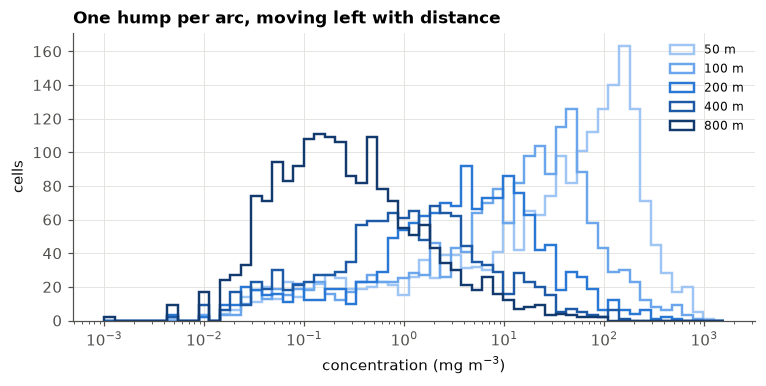

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(-3, 3.2, 60)
for arc in pgdata.ARCS_M:
    ax.hist(v[v.arc_m == arc].concentration_mg_m3.clip(lower=1e-3), bins=bins, histtype="step", lw=1.6,
            color=pgdata.ARC_COLORS[arc], label=f"{arc} m")
ax.set_xscale("log"); ax.set_xlabel("concentration (mg m$^{-3}$)"); ax.set_ylabel("cells")
ax.set_title("One hump per arc, moving left with distance"); ax.legend(fontsize=8); plt.show()

### The runs: ranges at a glance

Wind from near-calm to 9 m/s, temperature differences from a strong inversion to strong
lapse, and a direction swing (σθ) from 3° to over 25°. Ri_b is a bulk Richardson number:
negative means convective (daytime), positive means stable (night).

In [9]:
units = {"Q_g_s": "g/s", "u_ref": "m/s", "sigma_theta_source_10": "deg", "T_1m": "°C",
         "dT_16_05": "°C", "Ri_b": "-", "u_star": "m/s", "sigma_y_m_100": "m", "peak_100": "mg m-3"}
tab = rt[list(units)].astype(float).describe().T[["count", "min", "25%", "50%", "75%", "max"]]
tab.insert(0, "unit", pd.Series(units)); tab

,unit,count,min,25%,50%,75%,max
Q_g_s,g/s,68.0,38.500,43.325,79.650,98.950,104.100
u_ref,m/s,68.0,0.440,3.110,4.520,6.307,9.000
sigma_theta_source_10,deg,63.0,3.200,5.700,7.300,10.650,25.600
T_1m,°C,68.0,15.150,20.025,24.425,30.575,36.060
dT_16_05,°C,58.0,-7.930,-2.465,0.510,1.447,6.380
Ri_b,-,66.0,-0.755,-0.076,0.009,0.050,0.447
u_star,m/s,68.0,0.074,0.232,0.324,0.425,0.657
sigma_y_m_100,m,68.0,3.859,6.654,11.317,17.268,48.211
peak_100,mg m-3,68.0,23.300,57.675,86.000,172.250,822.000


Two facts about the **design** of the experiment are worth knowing before any analysis.
Releases split almost evenly between day (convective) and night (stable), with only a few
near-neutral evenings. And the experimenters **chose the release rate by time of day**: about
100 g/s by day and 40–50 g/s at night. So Q correlates with stability through the design, not
the physics. Divide concentrations by Q (and by wind speed) before comparing runs.

In [10]:
rt.groupby(["day_night", "regime"], observed=True).agg(runs=("Q_g_s", "size"), Q_median=("Q_g_s", "median"),
                                                        u_median=("u_ref", "median"))

runs  Q_median  u_median
day_night regime                                
day       convective      32      98.6     6.195
night     near-neutral     3      41.2     6.220
          stable          31      43.4     3.330

## 6. Data quality: what to trust, and how much

Every cell says how it was read. In Volume I, all concentrations were read by OCR and
cross-checked; the 162 that disagreed with an earlier transcription were settled by a person
against the scan (`value_source = owner review`). Volume II has a `quality` column; most cells
were read by two independent readers who agreed.

In [11]:
t81 = pd.read_csv(pgdata.v2("table_8.1.csv"), dtype=str, keep_default_na=False)
pd.crosstab(t81.section, t81.quality, margins=True)

quality,context,owner,printed_inconsistent,rule,single_reader,two_readers,All
section,,,,,,,
precipitation,0,12,0,0,59,0,71
radiation,2,1,1,0,0,209,213
soil_temperature_change,17,14,0,0,1,536,568
temperature,10,27,10,3,1,943,994
vapor_pressure,2,8,3,2,0,553,568
wind_direction,4,0,0,0,0,67,71
wind_speed,10,13,10,0,0,464,497
All,45,75,24,5,61,2772,2982


The curators' statements about specific cells live in `annotations/annotations.jsonl`, one per
line, keyed by file and `cell_id`. Each has a category:

In [12]:
ann, cats = pgdata.annotations(), pgdata.annotation_categories()
ann.category.value_counts().rename("n").to_frame().assign(meaning=lambda d: d.index.map(cats).str[:110])

,n,meaning
category,,
printed_inconsistent,256,"The owner confirmed the print, yet it fails a consistency check. No correction is proposed."
reading_decided_by_context,157,The readers disagreed; the kept reading fits the height profile or neighbouring hours and the al...
reading_decided_by_rule,24,The readers disagreed and the owner left it open; the reading under which the failed checks pass...
suspected_original_error,6,"Read correctly, but the curators suspect a typing error in the 1958 report. The printed value is..."
key_decided,3,"A row key (run, date) was smudged or unreadable and was set by a person."
unit_as_printed,2,The printed unit or heading is wrong; the dataset keeps it as printed.
unverified_transcription,1,"Kept as machine-read, not reviewed cell by cell."
excluded_table,1,A printed table left out of the dataset.
illegible,1,The owner could not read the print; no value.


The most interesting category is **suspected errors in the 1958 report itself**: the print is
clear, but the value contradicts its neighbours or another table. They are kept as printed and
the likely intended value is given beside them. If you use run 44 or run 10 at 800 m, read these first.

In [13]:
pd.set_option("display.max_colwidth", 120)
ann[ann.category == "suspected_original_error"][["file", "printed", "alternative", "evidence"]]

,file,printed,alternative,evidence
0,volume1/arcs.csv,9.565,0.565,"Print is clear (Mistral, Sonnet and owner agree). 18x its neighbours (0.505, 0.575), the only four-figure value in t..."
1,volume1/arcs.csv,0.90,0.090,"Print is clear. 12x its neighbours (0.050, 0.110), and the only two-decimal value in a column printed with three dec..."
2,volume1/slow_response_wind.csv,0135,0025,Every other release in Table 6.1 is printed 10 min before the Table 8.1 observation time (62 of 68). Release 60 is 0...
3,volume1/slow_response_wind.csv,,1956-08-27,"The Date cell is blank, so by the table's convention release 61 shares release 60's date (26 Aug.). Table 8.1 and th..."
4,volume1/slow_response_wind.csv,26 Aug.,27 Aug.,"Printed ""26 Aug.""; Table 8.1 and the Table 5.2 header (PDF 197, ""DATE 27 AUGUST 1956"") give 27 August. Probably prin..."
8,volume2/table_10.1.csv,1200,1700,"print is clear, but Table 8.1 (1705) and Table 12.1 (1658 sounding) place release 45 at about 1700; the owner judges..."


**In short**

- Long format, one row per printed cell; `status` says what a cell means, a blank is not missing.
- Join on run (`run` = `release`), read as a string.
- Normalise by Q and wind before comparing runs: the release rate was set by time of day.
- Quality is recorded per cell, and suspected misprints come with evidence and an alternative.

Next: **notebook 2**, what all this looks like in the field.